In [1]:
import pandas as pd

data = pd.read_csv("../data/customer_churn_dataset-testing-master.csv")

print(data.shape)
print(data.columns)
print(data.duplicated().sum())
print(data.isnull().sum())
print(data.info())
print(data['Churn'].value_counts())
print(data.head())

(64374, 12)
Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')
0
CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-nul

In [2]:
data.describe()
print(data['Gender'].value_counts())
print(data['Subscription Type'].value_counts())
print(data['Contract Length'].value_counts())

print(data.groupby("Churn")[["Age",'Tenure',"Usage Frequency","Support Calls","Payment Delay","Total Spend","Last Interaction"]].mean())

Gender
Female    34353
Male      30021
Name: count, dtype: int64
Subscription Type
Standard    21502
Basic       21451
Premium     21421
Name: count, dtype: int64
Contract Length
Monthly      22130
Annual       21410
Quarterly    20834
Name: count, dtype: int64
             Age     Tenure  Usage Frequency  Support Calls  Payment Delay  \
Churn                                                                        
0      41.132700  28.826481        16.042915       4.500753      12.453086   
1      42.902404  35.515200        14.010593       6.400617      22.334897   

       Total Spend  Last Interaction  
Churn                                 
0       560.541956         15.521944  
1       519.336143         15.473191  


In [3]:
print(pd.crosstab(data["Contract Length"],data["Churn"],normalize='index'))
print(pd.crosstab(data["Subscription Type"],data["Churn"],normalize='index'))
print(pd.crosstab(data["Gender"],data["Churn"],normalize='index'))


Churn                   0         1
Contract Length                    
Annual           0.537833  0.462167
Monthly          0.483913  0.516087
Quarterly        0.559518  0.440482
Churn                     0         1
Subscription Type                    
Basic              0.517225  0.482775
Premium            0.535036  0.464964
Standard           0.526695  0.473305
Churn          0         1
Gender                    
Female  0.449510  0.550490
Male    0.614203  0.385797


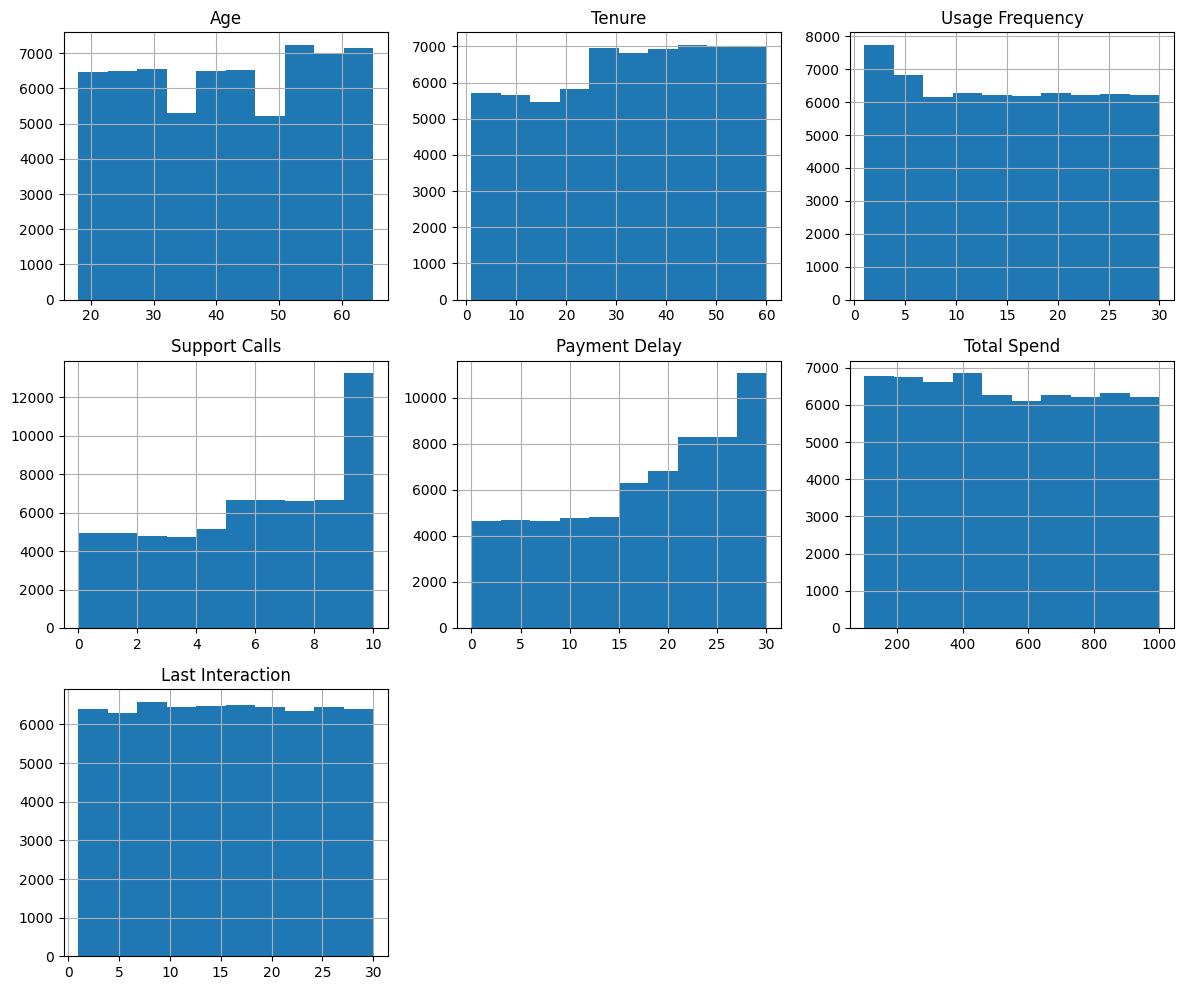

In [4]:
import matplotlib.pyplot as plt

data[[
    "Age",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction"
]].hist(figsize=(12, 10))

plt.tight_layout()
plt.show()

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,64374.0,32187.500000,18583.317451,1.0,16094.25,32187.5,48280.75,64374.0
Age,64374.0,41.970982,13.924911,18.0,30.00,42.0,54.00,65.0
Tenure,64374.0,31.994827,17.098234,1.0,18.00,33.0,47.00,60.0
Usage Frequency,64374.0,15.080234,8.816470,1.0,7.00,15.0,23.00,30.0
Support Calls,64374.0,5.400690,3.114005,0.0,3.00,6.0,8.00,10.0
Payment Delay,64374.0,17.133952,8.852211,0.0,10.00,19.0,25.00,30.0
Total Spend,64374.0,541.023379,260.874809,100.0,313.00,534.0,768.00,1000.0
Last Interaction,64374.0,15.498850,8.638436,1.0,8.00,15.0,23.00,30.0
Churn,64374.0,0.473685,0.499311,0.0,0.00,0.0,1.00,1.0


In [6]:
data["AverageSpendPerTenure"] = data["Total Spend"] / data["Tenure"]
data ["SupportCallsPerTenure"] = data ["Support Calls"] / data["Tenure"]

In [7]:
data[[
    "Tenure",
    "Total Spend",
    "AverageSpendPerTenure",
    "Support Calls",
    "SupportCallsPerTenure"
]].describe()

,Tenure,Total Spend,AverageSpendPerTenure,Support Calls,SupportCallsPerTenure
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,31.994827,541.023379,38.602260,5.400690,0.372214
std,17.098234,260.874809,83.844859,3.114005,0.853217
min,1.000000,100.000000,1.683333,0.000000,0.000000
25%,18.000000,313.000000,9.768201,3.000000,0.089286
50%,33.000000,534.000000,16.800000,6.000000,0.170213
75%,47.000000,768.000000,30.894636,8.000000,0.300000
max,60.000000,1000.000000,999.000000,10.000000,10.000000


In [8]:
data.corr(numeric_only=True)["Churn"].sort_values()

Usage Frequency         -0.115098
AverageSpendPerTenure   -0.110340
Total Spend             -0.078867
SupportCallsPerTenure   -0.038396
Last Interaction        -0.002818
Age                      0.063457
Tenure                   0.195327
Support Calls            0.304631
CustomerID               0.529832
Payment Delay            0.557386
Churn                    1.000000
Name: Churn, dtype: float64

In [9]:
data["CustomerID_Bin"] = pd.qcut(
    data["CustomerID"],
    q=10,
    duplicates="drop"
)

print(
    data.groupby("CustomerID_Bin")["Churn"].mean()
)

CustomerID_Bin
(0.999, 6438.3]       0.259087
(6438.3, 12875.6]     0.265496
(12875.6, 19312.9]    0.252757
(19312.9, 25750.2]    0.252718
(25750.2, 32187.5]    0.260525
(32187.5, 38624.8]    0.258195
(38624.8, 45062.1]    0.258931
(45062.1, 51499.4]    0.929160
(51499.4, 57936.7]    1.000000
(57936.7, 64374.0]    1.000000
Name: Churn, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_9468\3540869246.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("CustomerID_Bin")["Churn"].mean()


In [10]:
print(
    data.groupby("Churn")[
        ["AverageSpendPerTenure","SupportCallsPerTenure"]
    ].mean()
)

       AverageSpendPerTenure  SupportCallsPerTenure
Churn                                              
0                  47.378899               0.403293
1                  28.850470               0.337682


In [11]:
print(
    data.groupby("Churn")[
        ["AverageSpendPerTenure", "SupportCallsPerTenure"]
    ].median()
)

       AverageSpendPerTenure  SupportCallsPerTenure
Churn                                              
0                  19.733333                   0.15
1                  14.547170                   0.18


In [12]:
data.drop(columns=["CustomerID_Bin"], inplace=True)

In [13]:
X = data.drop(columns=["CustomerID","Churn"])
y = data["Churn"]

In [14]:
X.shape
X.columns

Index(['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend',
       'Last Interaction', 'AverageSpendPerTenure', 'SupportCallsPerTenure'],
      dtype='object')

In [15]:
y.value_counts()

Churn
0    33881
1    30493
Name: count, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [17]:
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(51499, 12)
(12875, 12)
Churn
0    0.526321
1    0.473679
Name: proportion, dtype: float64
Churn
0    0.526291
1    0.473709
Name: proportion, dtype: float64


In [18]:
numerical_features= X.select_dtypes(include=["number"]).columns.to_list()
categorical_features = X.select_dtypes(exclude=['number']).columns.to_list()
print("Numerical Data - ",numerical_features)
print("Categorical Data - ",categorical_features)

Numerical Data -  ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'AverageSpendPerTenure', 'SupportCallsPerTenure']
Categorical Data -  ['Gender', 'Subscription Type', 'Contract Length']


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ],
    remainder="drop"
)

print(numerical_features)
print(categorical_features)
print(preprocessor)

['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'AverageSpendPerTenure', 'SupportCallsPerTenure']
['Gender', 'Subscription Type', 'Contract Length']
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Gender', 'Subscription Type',
                                  'Contract Length']),
                                ('numerical', StandardScaler(),
                                 ['Age', 'Tenure', 'Usage Frequency',
                                  'Support Calls', 'Payment Delay',
                                  'Total Spend', 'Last Interaction',
                                  'AverageSpendPerTenure',
                                  'SupportCallsPerTenure'])])


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    [("preprocessor",preprocessor),
     ("classifier",LogisticRegression(max_iter=5000))
     ]
)

model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("accuracy : ",accuracy_score(y_test,y_pred))
print("precision",precision_score(y_test,y_pred))
print("recall",recall_score(y_test,y_pred))
print("f1 score",f1_score(y_test,y_pred))
print("Roc auc",roc_auc_score(y_test,y_prob))
print('avg precision',average_precision_score(y_test,y_prob))
print("classsification report",classification_report(y_test,y_pred))
print("confusion matrix",confusion_matrix(y_test,y_pred))

accuracy :  0.8276504854368932
precision 0.8136113805366958
recall 0.8252172487292999
f1 score 0.8193732193732194
Roc auc 0.9039097947618717
avg precision 0.8945620944851116
classsification report               precision    recall  f1-score   support

           0       0.84      0.83      0.84      6776
           1       0.81      0.83      0.82      6099

    accuracy                           0.83     12875
   macro avg       0.83      0.83      0.83     12875
weighted avg       0.83      0.83      0.83     12875

confusion matrix [[5623 1153]
 [1066 5033]]


In [21]:
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'Subscription Type',
                                                   'Contract Length']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'AverageSpendPerTenure',
                                                   'SupportCallsPerTenure'])])),
                ('classifier', LogisticRegression(max_iter=5000))])

In [22]:
def model_testing(y_test,y_pred,y_prob)->None:   
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1:", f1_score(y_test, y_pred))

    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print("PR-AUC:", average_precision_score(y_test, y_prob))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_accuracy = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

accuracy = logistic_accuracy['test_score']
print("mean accuracy : ",accuracy.mean())
print("std accuracy : ",accuracy.std())

mean accuracy :  0.8270259286178222
std accuracy :  0.005830908107856019


In [24]:
# calculating different parameters related evaluation for each hold
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

def validation(result):
    results = result
    accuracy_fold = results['test_accuracy']
    precision_fold = results['test_precision']
    recall_fold = results['test_recall']
    f1_fold = results['test_f1']
    roc_auc_fold = results['test_roc_auc']
    pr_auc_fold = results['test_pr_auc']

    print(f"mean accuracy for all folds : {accuracy_fold.mean()}\nstd in accuracy : {accuracy_fold.std()}")
    print(f"mean precision for all folds : {precision_fold.mean()}\nstd in precision : {precision_fold.std()}")
    print(f"mean recall for all folds : {recall_fold.mean()}\nstd in recall : {recall_fold.std()}")
    print(f"mean f1 score for all folds : {f1_fold.mean()}\nstd in f1 score : {f1_fold.std()}")
    print(f"mean roc auc for all folds : {roc_auc_fold.mean()}\nstd in roc auc : {roc_auc_fold.std()}")
    print(f"mean pr auc for all folds : {pr_auc_fold.mean()}\nstd in pr auc : {pr_auc_fold.std()}")

validation(results)

mean accuracy for all folds : 0.8270259286178222
std in accuracy : 0.005830908107856019
mean precision for all folds : 0.8104285758812821
std in precision : 0.007368100628948165
mean recall for all folds : 0.8287287410689232
std in recall : 0.005375319157135969
mean f1 score for all folds : 0.8194658107905688
std in f1 score : 0.0057750549591044165
mean roc auc for all folds : 0.9054546478337103
std in roc auc : 0.00387876314866836
mean pr auc for all folds : 0.8965729813886141
std in pr auc : 0.004517337383415753


In [25]:
# Random forest algorithm - bagging algorithm 

from sklearn.ensemble import RandomForestClassifier

random_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))
])

random_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'Subscription Type',
                                                   'Contract Length']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'AverageSpendPerTenure',
                                                   'SupportCallsPerTenure'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [26]:
random_scoring = cross_validate(
    random_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,

)

validation(random_scoring)

mean accuracy for all folds : 0.9984077405950431
std in accuracy : 0.00015770933418734798
mean precision for all folds : 0.9993019236554004
std in precision : 0.0003332191371499162
mean recall for all folds : 0.9973354103288932
std in recall : 0.0003429638025468693
mean f1 score for all folds : 0.9983176118391164
std in f1 score : 0.00016665051257568964
mean roc auc for all folds : 0.9999896931354886
std in roc auc : 3.6206668871797664e-06
mean pr auc for all folds : 0.999988210869527
std in pr auc : 4.098091849341111e-06


In [27]:
random_pipeline.fit(X_train,y_train)
y_pred_rf = random_pipeline.predict(X_test)
y_prob_rf = random_pipeline.predict_proba(X_test)[:,1]
model_testing(y_test,y_pred_rf,y_prob_rf)

Accuracy: 0.9982912621359223
Precision: 0.9991785772958764
Recall: 0.9972126578127561
F1: 0.9981946495978993
ROC-AUC: 0.9999925956081211
PR-AUC: 0.9999915668343877

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6776
           1       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg       1.00      1.00      1.00     12875


Confusion Matrix:
[[6771    5]
 [  17 6082]]


In [28]:
import pandas as pd

feature_names = (
    random_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = random_pipeline.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df.head(15).to_string(index=False))

                               Feature  Importance
              numerical__Payment Delay    0.438122
              numerical__Support Calls    0.097530
            numerical__Usage Frequency    0.086675
      numerical__SupportCallsPerTenure    0.071531
                     numerical__Tenure    0.069728
                numerical__Total Spend    0.040237
              categorical__Gender_Male    0.038152
                        numerical__Age    0.037674
      numerical__AverageSpendPerTenure    0.037389
            categorical__Gender_Female    0.037159
  categorical__Contract Length_Monthly    0.019533
   categorical__Contract Length_Annual    0.009668
categorical__Contract Length_Quarterly    0.006841
           numerical__Last Interaction    0.005819
  categorical__Subscription Type_Basic    0.001780


In [29]:
data.groupby(
    pd.qcut(data["CustomerID"], q=10, duplicates="drop"),
    observed=True
)["Churn"].agg(["count", "mean"])

,count,mean
CustomerID,,
"(0.999, 6438.3]",6438,0.259087
"(6438.3, 12875.6]",6437,0.265496
"(12875.6, 19312.9]",6437,0.252757
"(19312.9, 25750.2]",6438,0.252718
"(25750.2, 32187.5]",6437,0.260525
"(32187.5, 38624.8]",6437,0.258195
"(38624.8, 45062.1]",6438,0.258931
"(45062.1, 51499.4]",6437,0.929160
"(51499.4, 57936.7]",6437,1.000000


In [30]:
# training the model without payment feature cause check whether the model completely baised towards single feature
X_train_no_delay = X_train.drop(columns=["Payment Delay"])
new_numeric = X_train_no_delay.select_dtypes(include=["number"]).columns.to_list()
new_categorical = X_train_no_delay.select_dtypes(exclude=["number"]).columns.to_list()

new_preprocessor = ColumnTransformer([
    ("numerical",
     StandardScaler(),
     new_numeric),
    (
      "categorical",
      OneHotEncoder(handle_unknown='ignore'),
      new_categorical   
     ),
    ],
    remainder='drop'
    )

new_pipe_no_delay = Pipeline(
    [
        ("preprocessor",new_preprocessor),
        ("model",RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))
    ]
)

new_no_delay_result = cross_validate(
    new_pipe_no_delay,
    X_train_no_delay,
    y_train,
    cv=cv,
    scoring=scoring
)

validation(new_no_delay_result)

mean accuracy for all folds : 0.779005387458675
std in accuracy : 0.0008833052938945724
mean precision for all folds : 0.7076052750406154
std in precision : 0.0019174893708615586
mean recall for all folds : 0.9091581083878065
std in recall : 0.005587789799021889
mean f1 score for all folds : 0.7958041044273931
std in f1 score : 0.0012833967220454716
mean roc auc for all folds : 0.8483222182760273
std in roc auc : 0.0024917525496699192
mean pr auc for all folds : 0.8021797395200174
std in pr auc : 0.004178343556268135


In [31]:
print(
    data.groupby("Churn")["Payment Delay"]
    .describe()
)

print(
    pd.crosstab(
        pd.cut(data["Payment Delay"], bins=10),
        data["Churn"],
        normalize="index"
    ).round(3)
)

         count       mean       std  min   25%   50%   75%   max
Churn                                                           
0      33881.0  12.453086  8.308965  0.0   6.0  12.0  18.0  30.0
1      30493.0  22.334897  6.109532  0.0  19.0  23.0  27.0  30.0
Churn              0      1
Payment Delay              
(-0.03, 3.0]   0.896  0.104
(3.0, 6.0]     0.905  0.095
(6.0, 9.0]     0.896  0.104
(9.0, 12.0]    0.900  0.100
(12.0, 15.0]   0.898  0.102
(15.0, 18.0]   0.415  0.585
(18.0, 21.0]   0.343  0.657
(21.0, 24.0]   0.234  0.766
(24.0, 27.0]   0.236  0.764
(27.0, 30.0]   0.234  0.766


In [32]:
random_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'Subscription Type',
                                                   'Contract Length']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'AverageSpendPerTenure',
                                                   'SupportCallsPerTenure'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [33]:
import shap

# Use a smaller sample for faster analysis
X_sample = X_test.sample(
    n=500,
    random_state=42
)

# Apply the fitted preprocessing pipeline
X_sample_transformed = (
    random_pipeline
    .named_steps["preprocessor"]
    .transform(X_sample)
)

# Explain the Random Forest predictions
explainer = shap.TreeExplainer(
    random_pipeline.named_steps["model"]
)

shap_values = explainer.shap_values(
    X_sample_transformed
)

In [34]:
print(type(shap_values))

<class 'numpy.ndarray'>


In [35]:
print("SHAP shape:", shap_values.shape)
print("Transformed data shape:", X_sample_transformed.shape)
print("Model classes:", random_pipeline.named_steps["model"].classes_)

SHAP shape: (500, 17, 2)
Transformed data shape: (500, 17)
Model classes: [0 1]


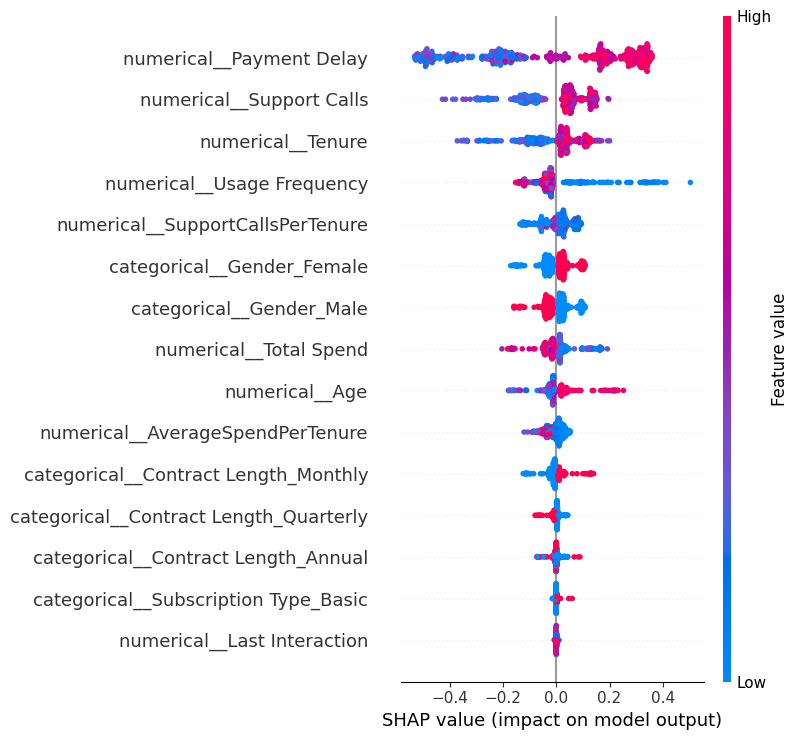

In [36]:
import matplotlib.pyplot as plt
import shap

# SHAP values for the churn class
shap_values_churn = shap_values[:, :, 1]

# Global explanation
shap.summary_plot(
    shap_values_churn,
    X_sample_transformed,
    feature_names=feature_names,
    max_display=15
)

In [37]:
import numpy as np
# Explain the first customer in our sample
customer_idx = 0

customer_shap = shap_values_churn[customer_idx]

# Show the five strongest contributions
top_indices = np.argsort(
    np.abs(customer_shap)
)[::-1][:5]

for idx in top_indices:
    print(
        feature_names[idx],
        round(customer_shap[idx], 4)
    )

numerical__Payment Delay -0.4616
numerical__Usage Frequency -0.1193
numerical__Support Calls 0.0616
numerical__Tenure 0.0421
numerical__Age 0.0367


In [38]:
import joblib

joblib.dump(
    random_pipeline,
    "../models/churn_pipeline.joblib"
)

['../models/churn_pipeline.joblib']

In [ ]:
# loading the model with feature engineering
# import joblib
# from feature_engineering import engineer_features

# model = joblib.load("churn_pipeline.joblib")

# # customer_df contains one row of raw customer input
# # customer_df = engineer_features(customer_df)

# prediction = model.predict(customer_df)
# probability = model.predict_proba(customer_df)[:, 1]


In [39]:
import pandas as pd

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    if (data["Tenure"] <= 0).any():
        raise ValueError("Tenure must be greater than zero.")

    data["AverageSpendPerTenure"] = (
        data["Total Spend"] / data["Tenure"]
    )

    data["SupportCallsPerTenure"] = (
        data["Support Calls"] / data["Tenure"]
    )

    return data


In [43]:
test_row = pd.DataFrame([{
    "Age": 35,
    "Gender": "Female",
    "Tenure": 24,
    "Usage Frequency": 18,
    "Support Calls": 3,
    "Payment Delay": 25,
    "Subscription Type": "Standard",
    "Contract Length": "Annual",
    "Total Spend": 600,
    "Last Interaction": 10
}])

test_row = engineer_features(test_row)

print(random_pipeline.predict_proba(test_row))

[[0.95 0.05]]
